# Build an Image Dataset Example

Build your own image dataset from image files (JPEG) stored on disk, with
Grain, and train a convolutional neural network on it, with Flax.

We will show 2 different ways to build that dataset:

- From a root folder, that will have a sub-folder containing images for each class:
```
    ROOT_FOLDER
       |-------- SUBFOLDER (CLASS 0)
       |             |
       |             | ----- image1.jpg
       |             | ----- image2.jpg
       |             | ----- etc...
       |
       |-------- SUBFOLDER (CLASS 1)
       |             |
       |             | ----- image1.jpg
       |             | ----- image2.jpg
       |             | ----- etc...
```

- From a plain text file, that will list all images with their class ID:
```
    /path/to/image/1.jpg CLASS_ID
    /path/to/image/2.jpg CLASS_ID
    /path/to/image/3.jpg CLASS_ID
    /path/to/image/4.jpg CLASS_ID
    etc...
```

In this example, the Oxford 17 Flowers images are arranged into such a root
folder (one sub-folder per flower species). To use your own images, change
the parameters marked 'CHANGE HERE' (such as the dataset path).

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

In [1]:
import os
import shutil
import sys
import tarfile

import grain
import jax.numpy as jnp
import numpy as np
import optax
from flax import nnx
from PIL import Image

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import DATA_DIR, download

# Dataset Parameters - CHANGE HERE
MODE = 'folder'  # or 'file', if you choose a plain text file (see above).
DATASET_PATH = os.path.join(DATA_DIR, 'flowers17')  # the dataset file or root folder path.

# Image Parameters
N_CLASSES = 17  # CHANGE HERE, total number of classes
IMG_HEIGHT = 64  # CHANGE HERE, the image height to be resized to
IMG_WIDTH = 64  # CHANGE HERE, the image width to be resized to
CHANNELS = 3  # The 3 color channels, change to 1 if grayscale

In [2]:
# Prepare the example dataset (skip this step to use your own images).
# Download and extract the Oxford 17 Flowers archive (like in 'load_data.py').
archive_path = download(["https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"],
                        "17flowers.tgz")
flowers_dir = os.path.join(DATA_DIR, "17flowers")
if not os.path.exists(flowers_dir):
    # Extract to a temporary folder, renamed once complete: an interrupted
    # extraction is then not mistaken for a complete one.
    shutil.rmtree(flowers_dir + ".tmp", ignore_errors=True)
    with tarfile.open(archive_path) as t:
        t.extractall(flowers_dir + ".tmp", filter="data")
    os.rename(flowers_dir + ".tmp", flowers_dir)
# Its 1360 images are 80 per flower species, in that order. Sort them into one
# sub-folder per species (with links: the images are not copied on disk).
flower_species = ['Daffodil', 'Snowdrop', 'LilyValley', 'Bluebell', 'Crocus', 'Iris',
                  'Tigerlily', 'Tulip', 'Fritillary', 'Sunflower', 'Daisy', 'ColtsFoot',
                  'Dandelion', 'Cowslip', 'Buttercup', 'Windflower', 'Pansy']
if not os.path.exists(DATASET_PATH):
    # Build the folders in a temporary folder, renamed once complete.
    shutil.rmtree(DATASET_PATH + ".tmp", ignore_errors=True)
    for i in range(1360):
        species_dir = os.path.join(DATASET_PATH + ".tmp", flower_species[i // 80])
        os.makedirs(species_dir, exist_ok=True)
        image_path = os.path.join(flowers_dir, "jpg", "image_%04i.jpg" % (i + 1))
        try:
            os.link(image_path, os.path.join(species_dir, os.path.basename(image_path)))
        except OSError:  # The file system doesn't support links: copy the image.
            shutil.copy(image_path, species_dir)
    os.rename(DATASET_PATH + ".tmp", DATASET_PATH)

In [3]:
# Reading the dataset
# 2 modes: 'file' or 'folder'
def read_images(dataset_path, mode, batch_size):
    imagepaths, labels = list(), list()
    if mode == 'file':
        # Read dataset file
        with open(dataset_path) as f:
            data = f.read().splitlines()
        for d in data:
            imagepaths.append(d.split(' ')[0])
            labels.append(int(d.split(' ')[1]))
    elif mode == 'folder':
        # An ID will be affected to each sub-folders by alphabetical order
        label = 0
        # List the directory
        classes = sorted(next(os.walk(dataset_path))[1])
        print("Classes (by label ID):", classes)
        # List each sub-directory (the classes)
        for c in classes:
            c_dir = os.path.join(dataset_path, c)
            walk = next(os.walk(c_dir))
            # Add each image to the training set
            for sample in sorted(walk[2]):
                # Only keeps jpeg images
                if sample.endswith('.jpg') or sample.endswith('.jpeg'):
                    imagepaths.append(os.path.join(c_dir, sample))
                    labels.append(label)
            label += 1
    else:
        raise Exception("Unknown mode.")

    # Read an image from disk, decode it, and resize it to a common size.
    def load_image(sample):
        imagepath, label = sample
        image = Image.open(imagepath).convert('RGB' if CHANNELS == 3 else 'L')
        image = image.resize((IMG_WIDTH, IMG_HEIGHT))
        image = np.array(image, np.float32).reshape(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
        # Normalize
        image = image * 1.0 / 127.5 - 1.0
        return image, label

    # Build a Grain dataset over the list of (image path, label) pairs.
    data = grain.MapDataset.source(list(zip(imagepaths, labels)))
    # Shuffle data, and refill it indefinitely (re-shuffled at every epoch).
    data = data.shuffle(seed=0).repeat()
    # Read images from disk.
    data = data.map(load_image)
    # Create batches.
    data = data.batch(batch_size, drop_remainder=True)
    # Load images in 4 parallel threads, preparing the next batches in advance.
    data = data.to_iter_dataset(grain.ReadOptions(num_threads=4, prefetch_buffer_size=8))

    return iter(data)

In [4]:
# -----------------------------------------------
# THIS IS A CLASSIC CNN (see examples, section 3)
# -----------------------------------------------

# Parameters
learning_rate = 0.001
num_steps = 500
batch_size = 32
display_step = 50

# Network Parameters
dropout = 0.25  # Dropout, probability to drop a unit

# Build the data input
train_data = read_images(DATASET_PATH, MODE, batch_size)

Classes (by label ID): ['Bluebell', 'Buttercup', 'ColtsFoot', 'Cowslip', 'Crocus', 'Daffodil', 'Daisy', 'Dandelion', 'Fritillary', 'Iris', 'LilyValley', 'Pansy', 'Snowdrop', 'Sunflower', 'Tigerlily', 'Tulip', 'Windflower']


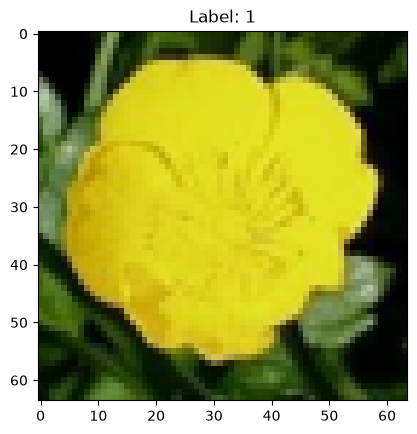

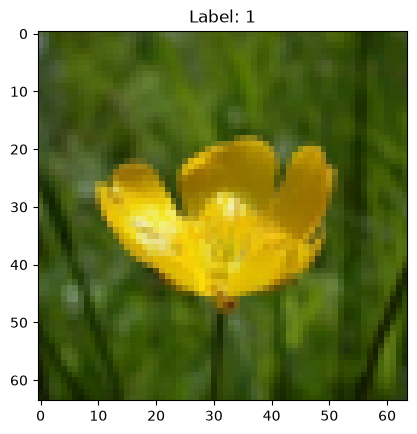

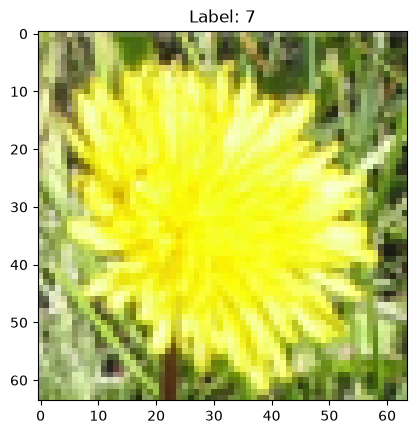

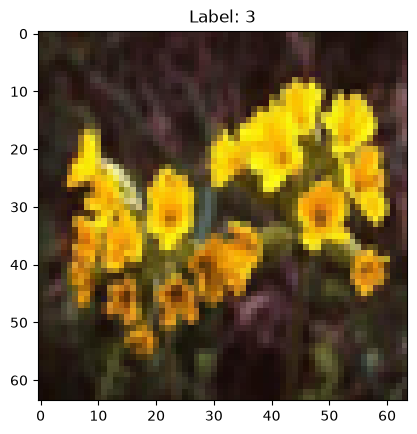

In [5]:
# Display a few images of the dataset, with their label.
import matplotlib.pyplot as plt

batch_x, batch_y = next(train_data)
for i in range(4):
    # Rescale values from [-1, 1] back to [0, 1] for display.
    plt.imshow(np.squeeze((batch_x[i] + 1.) / 2.), cmap='gray')
    plt.title("Label: %i" % batch_y[i])
    plt.show()

In [6]:
# Create model
class ConvNet(nnx.Module):
    def __init__(self, n_classes, dropout, rngs):
        # Convolution Layer with 32 filters and a kernel size of 5
        self.conv1 = nnx.Conv(CHANNELS, 32, kernel_size=(5, 5), padding='VALID', rngs=rngs)
        # Convolution Layer with 64 filters and a kernel size of 3
        self.conv2 = nnx.Conv(32, 64, kernel_size=(3, 3), padding='VALID', rngs=rngs)
        # Fully connected layer. Its input is the output of the layers above,
        # flattened: 'VALID' convolutions (no padding) make the images a bit
        # smaller and max pooling halves them, e.g. for 64x64 images:
        # conv 5x5 -> 60x60, pool -> 30x30, conv 3x3 -> 28x28, pool -> 14x14.
        flat_height = ((IMG_HEIGHT - 4) // 2 - 2) // 2
        flat_width = ((IMG_WIDTH - 4) // 2 - 2) // 2
        self.fc1 = nnx.Linear(flat_height * flat_width * 64, 1024, rngs=rngs)
        # Apply Dropout (only in training mode, see 'train()' and 'eval()' below)
        self.dropout = nnx.Dropout(dropout, rngs=rngs)
        # Output layer, class prediction
        self.out = nnx.Linear(1024, n_classes, rngs=rngs)

    def __call__(self, x):
        x = nnx.relu(self.conv1(x))
        # Max Pooling (down-sampling) with strides of 2 and kernel size of 2
        x = nnx.max_pool(x, window_shape=(2, 2), strides=(2, 2))
        x = nnx.relu(self.conv2(x))
        # Max Pooling (down-sampling) with strides of 2 and kernel size of 2
        x = nnx.max_pool(x, window_shape=(2, 2), strides=(2, 2))
        # Flatten the data to a 1-D vector for the fully connected layer
        x = x.reshape(x.shape[0], -1)
        x = self.dropout(nnx.relu(self.fc1(x)))
        # Return the raw scores (logits): the loss function applies softmax.
        return self.out(x)

In [7]:
# Build the model ('rngs' provides the random keys for weights init and dropout).
conv_net = ConvNet(N_CLASSES, dropout, rngs=nnx.Rngs(0))

# Define loss and optimizer
def cross_entropy_loss(logits, labels):
    loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=labels)
    return jnp.mean(loss)

# Evaluate model
def accuracy(logits, labels):
    correct_pred = jnp.equal(jnp.argmax(logits, 1), labels)
    return jnp.mean(correct_pred.astype(jnp.float32))

optimizer = nnx.Optimizer(conv_net, optax.adam(learning_rate), wrt=nnx.Param)

# Optimization process, compiled with XLA by @nnx.jit for speed.
@nnx.jit
def run_optimization(conv_net, optimizer, x, y):
    def loss_fn(conv_net):
        return cross_entropy_loss(conv_net(x), y)
    gradients = nnx.grad(loss_fn)(conv_net)
    optimizer.update(conv_net, gradients)

# Training cycle
# Note: the accuracy is measured on the training batch. With only 80 images
# per class, the network quickly learns them by heart: to measure how well it
# generalizes to new images, keep some images aside as a test set.
for step in range(1, num_steps + 1):
    batch_x, batch_y = next(train_data)
    # Training mode: dropout is applied.
    conv_net.train()
    run_optimization(conv_net, optimizer, batch_x, batch_y)

    if step % display_step == 0:
        # Evaluation mode: dropout is not applied.
        conv_net.eval()
        logits = conv_net(batch_x)
        loss = cross_entropy_loss(logits, batch_y)
        acc = accuracy(logits, batch_y)
        print("step: %i, loss: %f, training accuracy: %f" % (step, loss, acc))

# To save your model, see '4_Utils/save_restore_model.py'.

step: 50, loss: 1.385028, training accuracy: 0.625000


step: 100, loss: 0.683388, training accuracy: 0.750000


step: 150, loss: 0.442234, training accuracy: 0.906250


step: 200, loss: 0.184071, training accuracy: 0.968750


step: 250, loss: 0.043893, training accuracy: 1.000000


step: 300, loss: 0.015538, training accuracy: 1.000000


step: 350, loss: 0.008173, training accuracy: 1.000000


step: 400, loss: 0.004851, training accuracy: 1.000000


step: 450, loss: 0.001925, training accuracy: 1.000000


step: 500, loss: 0.000294, training accuracy: 1.000000
